In [2]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../')

import oasis_dla

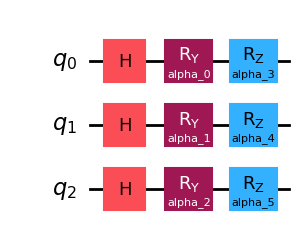

In [ ]:
vqls_rz = oasis_dla.VQLS(qubits=3, ansatz_type=1)
vqls_ry = oasis_dla.VQLS(qubits=3, ansatz_type=0)

vqls_ry.ansatz.draw('mpl')
vqls_rz.ansatz.draw('mpl')

In [ ]:
A_0 = np.eye(8) # 2^3
A_1 = 0.2 * np.kron(np.kron(oasis_dla.X, oasis_dla.Z), np.eye(2))
A_2 = 0.2 * np.kron(np.kron(oasis_dla.X, np.eye(2)), np.eye(2))
A = A_0 + A_1 + A_2

b = np.ones(8) / np.sqrt(8)

res = vqls.solve(A, b)
q_soln = res.solution()
c_soln = np.linalg.solve(A, b)

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.2815083156046967e-14
       x: [-2.885e-07  3.303e-01  6.833e-08 -3.753e-08  1.799e-07
            4.647e-07]
     nit: 68
   maxcv: 0.0
    nfev: 73


array([[0.25253816-7.66479123e-08j],
       [0.25253809-8.61253091e-08j],
       [0.35355343-4.37159896e-08j],
       [0.35355333-5.69843638e-08j],
       [0.25253818+4.07031243e-08j],
       [0.2525381 +3.12256931e-08j],
       [0.35355346+1.20575471e-07j],
       [0.35355336+1.07307048e-07j]])

In [12]:
display(q_soln)
display(c_soln)

vqls.compute_accuracy(q_soln, c_soln)

array([[0.25253816-7.66479123e-08j],
       [0.25253809-8.61253091e-08j],
       [0.35355343-4.37159896e-08j],
       [0.35355333-5.69843638e-08j],
       [0.25253818+4.07031243e-08j],
       [0.2525381 +3.12256931e-08j],
       [0.35355346+1.20575471e-07j],
       [0.35355336+1.07307048e-07j]])

array([0.25253814, 0.25253814, 0.35355339, 0.35355339, 0.25253814,
       0.25253814, 0.35355339, 0.35355339])

np.float64(0.4285714039829478)

In [13]:
res

Scaled Solution: [[0.25253816-7.66479123e-08j]
 [0.25253809-8.61253091e-08j]
 [0.35355343-4.37159896e-08j]
 [0.35355333-5.69843638e-08j]
 [0.25253818+4.07031243e-08j]
 [0.2525381 +3.12256931e-08j]
 [0.35355346+1.20575471e-07j]
 [0.35355336+1.07307048e-07j]]

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.4710455076283324e-14
       x: [-4.801e-08  3.303e-01 -3.217e-07  3.616e-08 -2.136e-07
            2.500e-07]
     nit: 57
   maxcv: 0.0
    nfev: 62
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.4099832412739488e-14
       x: [ 2.965e-07  3.303e-01 -1.021e-07 -1.470e-07 -1.288e-07
            2.067e-07]
     nit: 60
   maxcv: 0.0
    nfev: 65
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 6.439293542825908e-15
       x: [ 8.195e-08  3.303e-01  1.772e-07  5.533e-08 -1.572e-07
            1.151e-07]
     nit: 70
   maxcv: 0.0
    nfev: 82
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 3.3861802251067274e-14
       x: [ 9.188e-08  3.303e-01 -3.639e-07 -1.744e-08 -9.643e-08
           -5.345e-07]
 

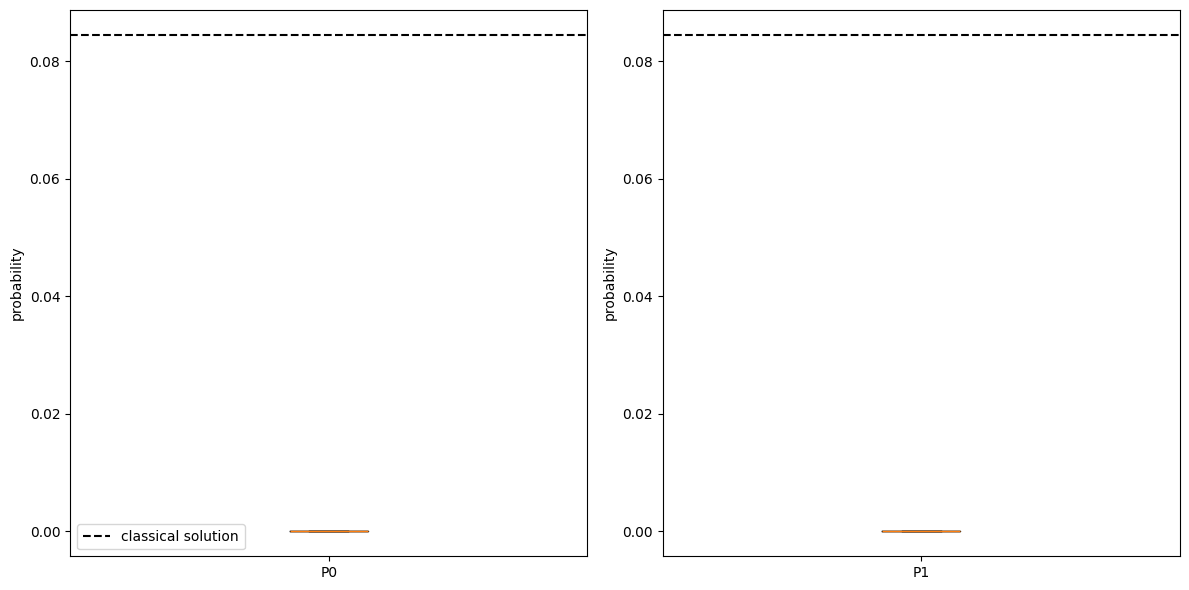

In [14]:
prob_list = []
for i in range(0, 20):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")


P0s = [probs.get("0", 0) for probs in prob_list]
P1s = [probs.get("1", 0) for probs in prob_list]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, data, p_true, label in zip(axes, [P0s, P1s], p_classical, ["P0", "P1"]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
plt.tight_layout()
plt.show()